# Automobile Sales During Recessions

Course project from  IBM Data Analyst Professional Certificate Course *Data Visualization with Python*. The dataset contains simulated automobile sales.

# Data Overview

The dataset used for this visualization assignment contains automobile_sales data representing automobile sales and related variables during recession and non-recession period.

The dataset includes the following variables:
1.  Date: The month end date of sales observation.
2.  Recession: A binary variable indicating recession perion; 1 means it was recession, 0 means it was normal.
3.  Automobile_Sales: The number of vehicles sold during the period.
4.  GDP: The per capita GDP value in USD.
5.  Unemployment_Rate: The monthly unemployment rate.
6.  Consumer_Confidence: A synthetic index representing consumer confidence, which can impact consumer spending and automobile purchases.
7.  Seasonality_Weight: The weight representing the seasonality effect on automobile sales during the period. This variable represents the seasonal effect on automobile sales for a given month. In the automobile industry, sales often fluctuate throughout the year due to seasonal patterns—for example, sales may increase during the festive season or year-end promotions, and decrease during off-peak months like post-holiday winter periods. A value greater than 1 indicates higher-than-average sales expected for that month due to seasonal trends (e.g., holiday season or new model launches). A value less than 1 suggests lower-than-average sales due to seasonal slowdowns. A value around 1 means the season has neutral or average effect on sales.
8.  Price: The average vehicle price during the period.
9.  Advertising_Expenditure: The advertising expenditure of the company.
10. Vehicle_Type: The type of vehicles sold; Supperminicar, Smallfamiliycar, Mediumfamilycar, Executivecar, Sports.
11. Competition: The measure of competition in the market, such as the number of competitors or market share of major manufacturers.
12. Month: Month of the observation extracted from Date..
13. Year: Year of the observation extracted from Date. 

### Importing Required Libraries

In [3]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import folium

## Importing Data

In [4]:
import requests
import io
import pandas as pd

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/d51iMGfp_t0QpO30Lym-dw/automobile-sales.csv"

response = requests.get(URL)

response.raise_for_status()

csv_content = io.StringIO(response.text)

df = pd.read_csv(csv_content)

print('Data downloaded and read into a dataframe!')

print(df.head())

Data downloaded and read into a dataframe!
         Date  Year Month  Recession  Consumer_Confidence  Seasonality_Weight  \
0  1980-01-31  1980   Jan          1               108.24                0.45   
1  1980-01-31  1980   Jan          1               108.24                0.45   
2  1980-01-31  1980   Jan          1               108.24                0.36   
3  1980-01-31  1980   Jan          1               108.24                0.38   
4  1980-02-29  1980   Feb          1                98.75                0.46   

   Price  Advertising_Expenditure  Competition    GDP  Growth_Rate  \
0  27704                   1417.5            7  60.22         0.01   
1  77270                    763.7            7  60.22         0.01   
2  19665                   1417.5            7  60.22         0.01   
3  36986                   1417.5            7  60.22         0.01   
4  26609                   2773.4            4  45.99        -0.31   

   unemployment_rate  Automobile_Sales     Vehicl

In [4]:
df.describe()

,Year,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales
count,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000
mean,2001.520833,0.224432,101.210890,0.737756,41469.506155,2879.743655,6.118845,40.205748,-0.237074,2.441525,3164.160511
std,12.535031,0.417306,10.634092,0.286092,21388.409141,1175.338324,1.964292,16.291271,0.859691,1.108472,3640.137399
min,1980.000000,0.000000,73.900000,0.250000,15001.000000,494.200000,3.000000,12.510000,-4.230000,1.000000,40.000000
25%,1991.000000,0.000000,94.060000,0.500000,22039.000000,1872.000000,4.000000,27.210000,-0.570000,1.600000,923.000000
50%,2002.000000,0.000000,100.800000,0.810000,34957.500000,2883.500000,6.000000,39.420000,-0.005000,2.300000,2381.500000
75%,2012.000000,0.000000,108.320000,0.940000,57418.250000,3902.425000,8.000000,53.862500,0.392500,2.900000,4363.500000
max,2023.000000,1.000000,131.670000,1.500000,79998.000000,4983.000000,9.000000,70.370000,0.820000,6.000000,65645.000000


In [5]:
df.columns

Index(['Date', 'Year', 'Month', 'Recession', 'Consumer_Confidence',
       'Seasonality_Weight', 'Price', 'Advertising_Expenditure', 'Competition',
       'GDP', 'Growth_Rate', 'unemployment_rate', 'Automobile_Sales',
       'Vehicle_Type', 'City'],
      dtype='str')

## 1. How did average automobile sales change over time?

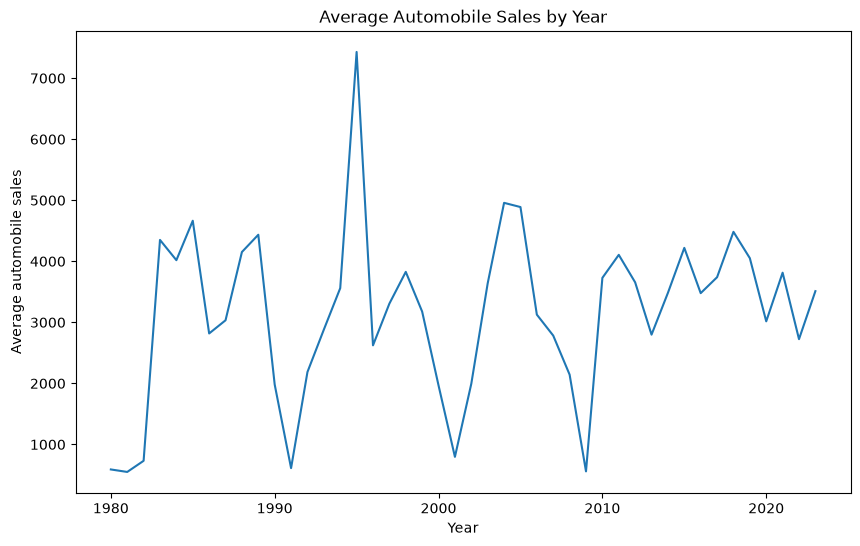

In [23]:
plt.figure(figsize = (10,6))
df_new = df.groupby('Year')['Automobile_Sales'].mean()

df_new.plot(kind = "line")
plt.xlabel('Year')
plt.ylabel('Average automobile sales')
plt.title('Average Automobile Sales by Year')
plt.show()


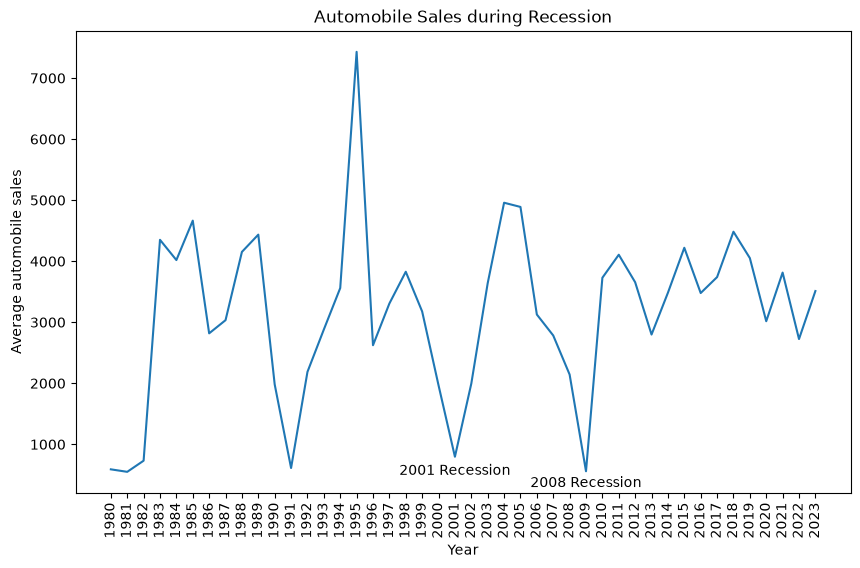

In [7]:
years = list(range(1980, 2024))

plt.figure(figsize = (10,6))
df_new = df.groupby('Year')['Automobile_Sales'].mean()

df_new.plot(kind = "line")
plt.xticks(years, rotation = 90)
plt.text(2001, 500, '2001 Recession', ha = 'center')
plt.text(2009, 300, '2008 Recession', ha = 'center')

plt.xlabel('Year')
plt.ylabel('Average automobile sales')
plt.title('Automobile Sales during Recession')

plt.show()


**Conclusion.** Average sales changed a lot from year to year. The highest average was in 1995 and the lowest was in 1981.

## 2. How do advertising expenditure and automobile sales move outside recessions?

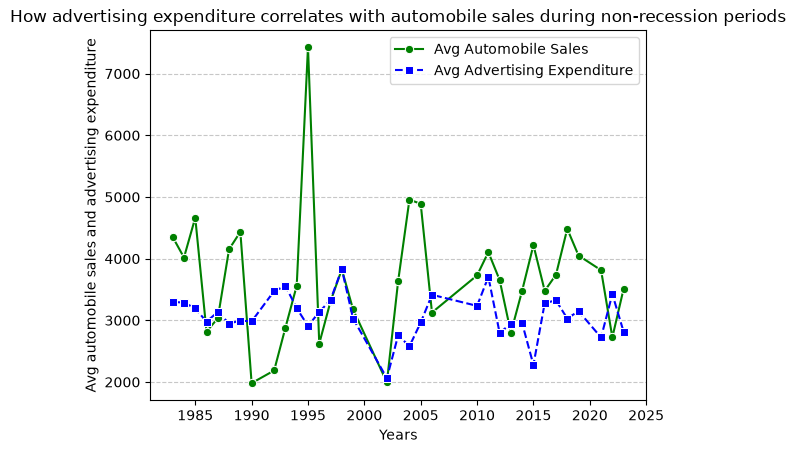

In [8]:
df_nonrecession = df[df['Recession']==0]
df_nonrecession = df_nonrecession.groupby('Year')[['Automobile_Sales', 'Advertising_Expenditure']].mean()
df_nonrecession = df_nonrecession.reset_index()
sns.lineplot(data = df_nonrecession, x="Year", y="Automobile_Sales", color = 'green', marker = 'o', label = 'Avg Automobile Sales')
sns.lineplot(data = df_nonrecession, x="Year", y="Advertising_Expenditure", color = "blue", marker = 's', linestyle = '--', label = 'Avg Advertising Expenditure')

plt.xlabel('Years')
plt.ylabel('Avg automobile sales and advertising expenditure')
plt.title('How advertising expenditure correlates with automobile sales during non-recession periods')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)


In [ ]:
#We can see that sales spike differently. Automobile sales are in general more volatile, and while there are moments of alignment 
#the correlation is not close to each other suggesting that other factors like market demand, economic conditions play significant role
#in general, correlation is incosistent

**Conclusion.** In some years sales and ad spending move in the same direction, but the pattern changes over time. A correlation coefficient would help measure the relationship.

## 3. How did average sales compare during recessions and other periods?

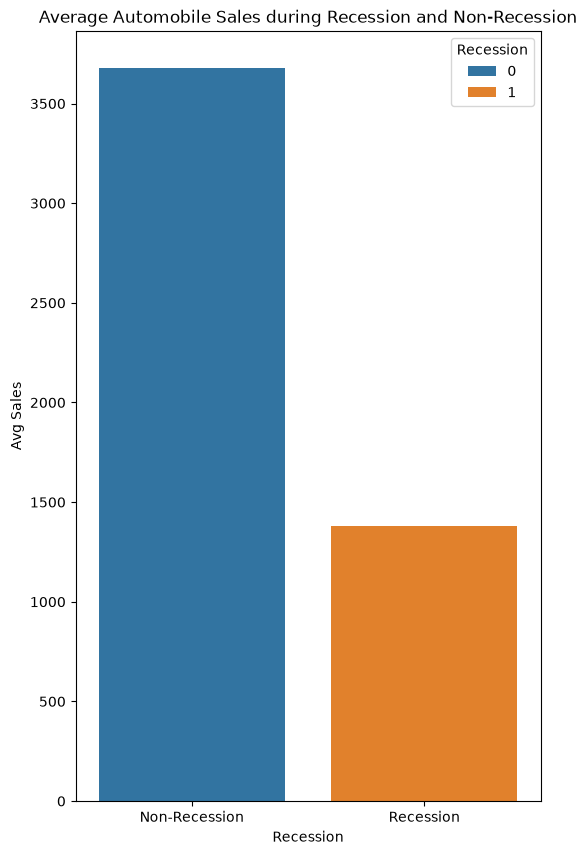

In [9]:
new_df = df.groupby('Recession')['Automobile_Sales'].mean().reset_index()
plt.figure(figsize = (6,10))
sns.barplot(x='Recession', y='Automobile_Sales', hue='Recession',  data=new_df)
plt.ylabel('Avg Sales')
plt.title('Average Automobile Sales during Recession and Non-Recession')
plt.xticks(ticks=[0, 1], labels=['Non-Recession', 'Recession'])
plt.show()

**Conclusion.** Average sales were lower during recessions, at around 1,382 per record compared with 3,680 in other periods.

### How did sales compare by vehicle type?

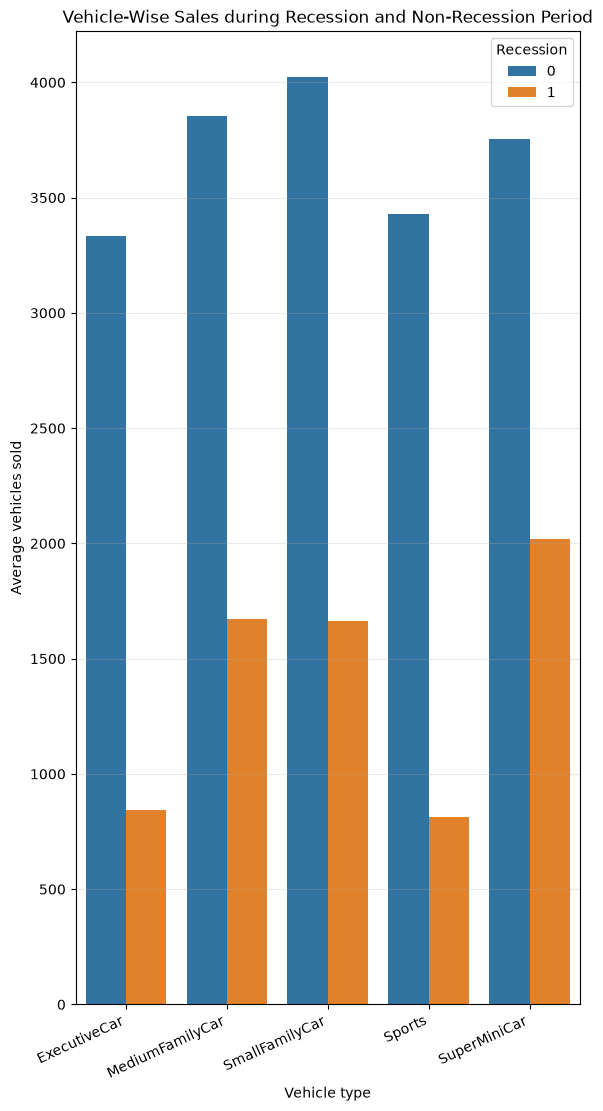

In [10]:
new_df1 = df.groupby(['Vehicle_Type','Recession'])['Automobile_Sales'].mean().reset_index()
plt.figure(figsize = (6,11))
sns.barplot(x='Vehicle_Type', y='Automobile_Sales', hue='Recession',  data=new_df1)
plt.xticks(rotation=25, ha='right')
plt.xlabel('Vehicle type')
plt.ylabel('Average vehicles sold')
plt.grid(True, axis='y', alpha=0.25)
plt.tight_layout()
plt.title('Vehicle-Wise Sales during Recession and Non-Recession Period')

plt.show()

**Conclusion**

From this plot we can see that there is a drastic decrease in sales while during recession.  Most affected are sports and executive cars.

## 4. How did GDP vary during recessions and other periods?

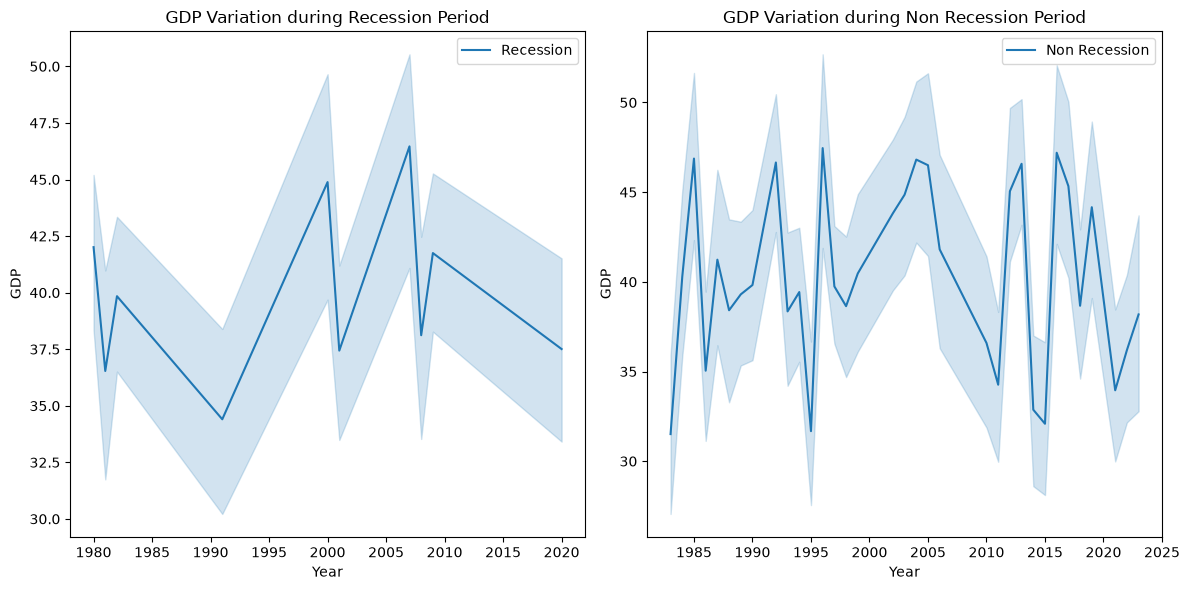

In [11]:
recession_data = df[df['Recession'] ==1]
non_recession_data = df[df['Recession']==0]
fig=plt.figure(figsize=(12,6))

ax0=fig.add_subplot(1,2,1)
ax1=fig.add_subplot(1,2,2)

sns.lineplot(x='Year', y='GDP', data = recession_data, label='Recession', ax=ax0)
ax0.set_xlabel('Year')
ax0.set_ylabel('GDP')
ax0.set_title('GDP Variation during Recession Period')

sns.lineplot(x='Year', y='GDP', data = non_recession_data, label='Non Recession', ax=ax1)
ax1.set_xlabel('Year')
ax1.set_ylabel('GDP')
ax1.set_title('GDP Variation during Non Recession Period')
plt.tight_layout()
plt.show()

#GDP during reccessions shows lower overall GDP and higher volatility, however non recession period also have some variations

**Conclusion.** GDP goes up and down in both plots. The average GDP in the underlying records is similar for the two groups, at about 40 in the dataset’s units.

## 5. Which months had higher sales outside recessions?

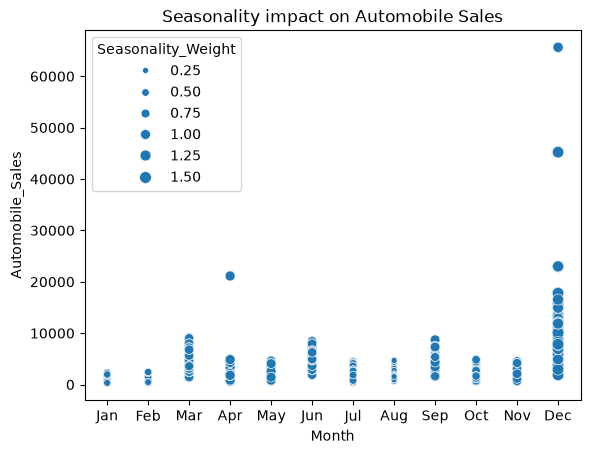

In [12]:
non_rec_data = df[df['Recession'] == 0]
size = non_rec_data['Seasonality_Weight']
sns.scatterplot(x='Month', y='Automobile_Sales', size = size, data = non_rec_data)
plt.title('Seasonality impact on Automobile Sales')
plt.xlabel('Month')
plt.ylabel('Automobile_Sales')
plt.show()

#From this plot, it is evident that seasonality has not affected on the overall sales. However, there is a drastic raise in sales in the month of April and December

**Conclusion.** December stands out for high sales outside recessions. January and February tend to have lower sales, while April has a few unusually high observations.

## 6. How do consumer confidence and vehicle price relate to sales during recessions?

Text(0.5, 1.0, 'Consumer Confidence and Automobile Sales during Recessions')

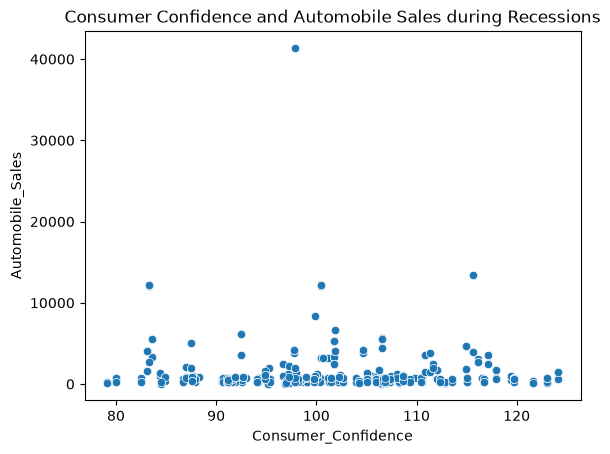

In [13]:
rec_data = df[df['Recession'] == 1]
sns.scatterplot(data = rec_data, x='Consumer_Confidence', y = 'Automobile_Sales')
plt.title('Consumer Confidence and Automobile Sales during Recessions')

**Conclusion.** The points are spread out. There is little sign of a clear link between consumer confidence and sales in this plot.

### Vehicle price and sales

Text(0.5, 1.0, 'Relationship between Vehicle Price and Sales during Recessions')

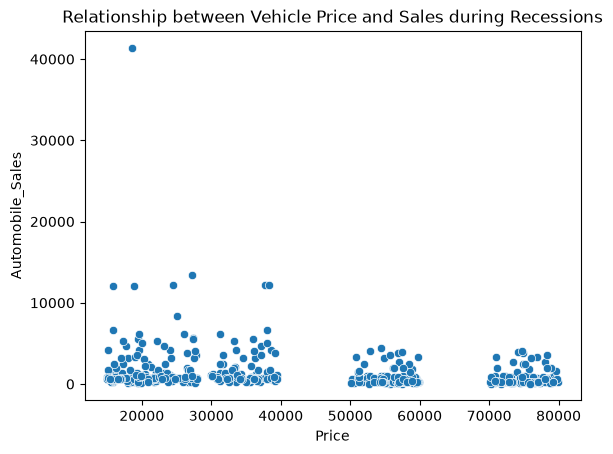

In [14]:
rec_data = df[df['Recession'] == 1]
sns.scatterplot(data = rec_data, x='Price', y = 'Automobile_Sales')
plt.title('Relationship between Vehicle Price and Sales during Recessions')


**Conclusion.** Higher prices tend to go with somewhat lower sales, but there is plenty of variation at similar prices.

## 7. How much was spent on advertising in recession and non-recession periods?

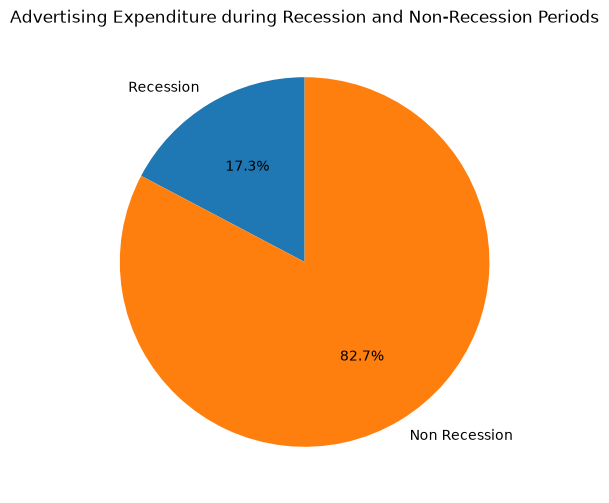

In [15]:
rec_data = df[df['Recession'] == 1]
non_rec_data = df[df['Recession'] == 0]
rec_sum = rec_data['Advertising_Expenditure'].sum()
non_rec_sum = non_rec_data['Advertising_Expenditure'].sum()
plt.figure(figsize = (8,6))
labels = ['Recession', 'Non Recession']
sizes = [rec_sum, non_rec_sum]
plt.pie(sizes, labels = labels, autopct='%1.1f%%', startangle=90)
plt.title('Advertising Expenditure during Recession and Non-Recession Periods')
plt.show()

**Conclusion**

Seems that XYZAutomotives is spending much more on ads during non recession periods in comparison to recession times

That compares the totals for each group. The dataset has more records outside recessions, which matters when comparing those totals.

## 8. Which vehicle types had the largest share of advertising spending during recessions?

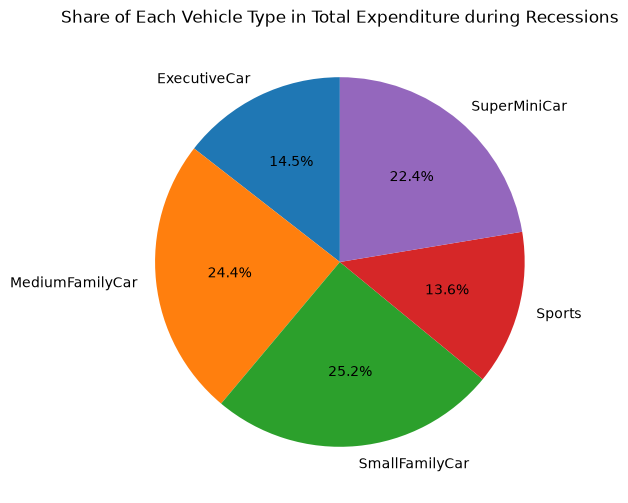

In [16]:
rec_data = df[df['Recession'] == 1]
rec_sum1 = rec_data.groupby('Vehicle_Type')['Advertising_Expenditure'].sum()
plt.figure(figsize = (8,6))
labels = rec_sum1.index
sizes = rec_sum1.values
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title('Share of Each Vehicle Type in Total Expenditure during Recessions')
plt.show()
#During recession the advertisements were mostly focued on low price range vehicle.

**Conclusion.** Small family cars took the largest share of advertising spending during recessions, with medium family cars close behind.

## 9. How did sales vary with unemployment during recessions?

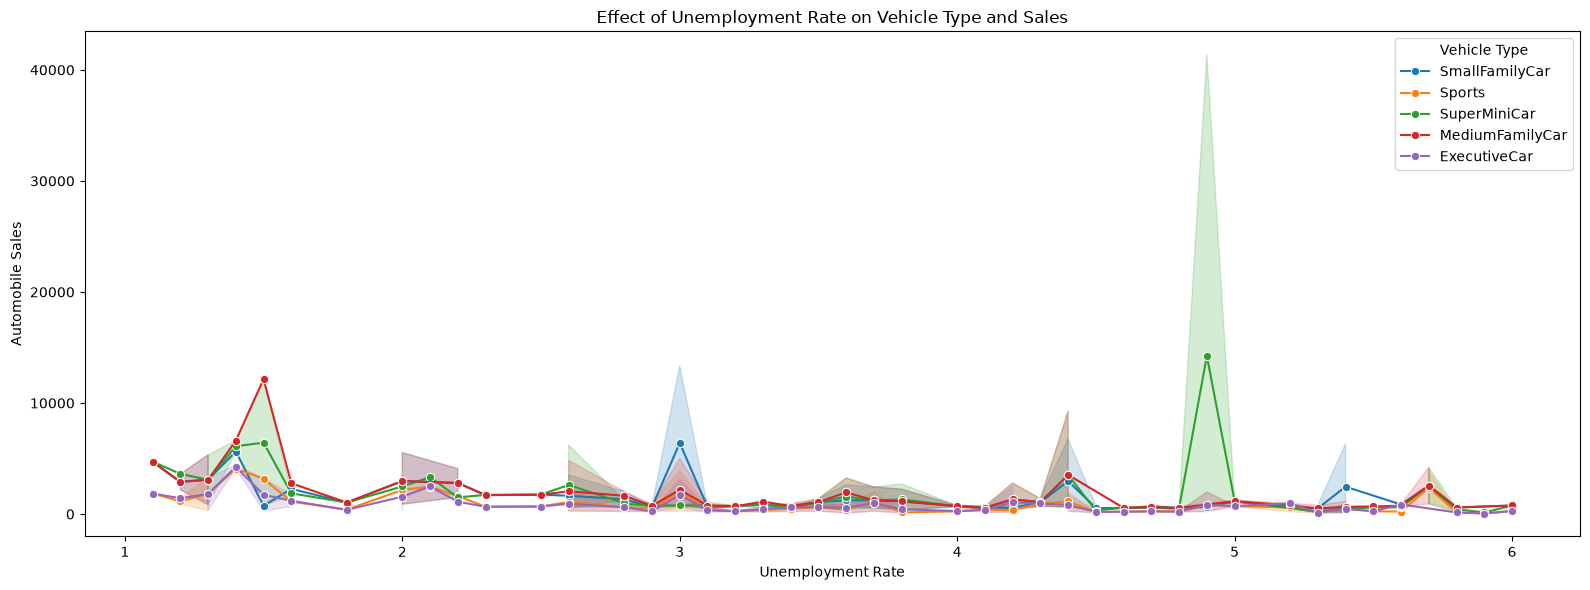

In [17]:
rec_data = df[df['Recession'] == 1]

plt.figure(figsize=(16,6))
sns.lineplot(data= rec_data, x='unemployment_rate', y='Automobile_Sales', hue='Vehicle_Type', marker = 'o')
plt.title('Effect of Unemployment Rate on Vehicle Type and Sales')
plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.legend(title='Vehicle Type')
plt.tight_layout()

**Conclusion.** The relationship varies by vehicle type. Sales tend to fall more clearly as unemployment rises for executive cars, while the pattern is weaker for superminis.

## 10. Where were recession sales highest?

In [6]:
import requests

url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/us-states.json'
filename = "us-states.json"

response = requests.get(url, timeout=30)
response.raise_for_status()

with open(filename, "wb") as f:
    f.write(response.content)

In [11]:
recession_data = df[df['Recession'] == 1]

sales_by_city = recession_data.groupby('City')['Automobile_Sales'].sum().reset_index()

map1 = folium.Map(location=[37.0902, -95.7129], zoom_start=4, tiles=None)

choropleth = folium.Choropleth(
    geo_data= 'us-states.json',  # GeoJSON file with state boundaries
    data=sales_by_city,
    columns=['City', 'Automobile_Sales'],
    key_on='feature.properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name='Automobile Sales during Recession'
).add_to(map1)


choropleth.geojson.add_child(
    folium.features.GeoJsonTooltip(['name'], labels=True)
)
from pathlib import Path

from pathlib import Path

from IPython.display import Image

Image(filename="recession-sales-map.png")

map1

**Conclusion.** California had the highest total recession sales across the four locations in this dataset.

**Overall conclusion**

In this simulated dataset, average vehicle sales were around 1,382 per record during recessions and 3,680 outside recessions. That is a difference of about 62.5%. Average sales were lower across all five vehicle types, although the size of the gap varied. Sports cars and executive cars had the largest percentage differences, at around 76% and 75%, respectively. Superminis had the smallest difference, at around 46%. Looking at the results by vehicle type shows how much variation the overall average hides.

The other charts help put this comparison in context. Outside recessions, December stood out for higher sales, while January and February tended to be weaker. This means that the mix of months covered by each group could affect the comparison. Total advertising spending was also lower in recession periods, which contained 474 records compared with 1,638 outside recessions. Comparing average spending per record would help account for the difference in group size.

I interpret these results as descriptive comparisons within a simulated dataset. Applying what I learned in QRM, my next question would be whether the sales gap persists after accounting for vehicle type and calendar month. For example, I could compare sports-car sales in December across both periods, then repeat that comparison for other months and vehicle types. That would give me a clearer view of whether the pattern holds when comparing similar observations.